# 03 · Preprocessing & Feature Engineering

This notebook turns the clean table into model-ready matrices and **chooses each preprocessing step with evidence** (cross-validation inside the training set only):

1. Train / test split (stratified by diagnosis *and* site)
2. Feature engineering
3. Multicollinearity check (VIF)
4. Imputation strategy comparison
5. Scaling comparison
6. Class-imbalance strategy comparison (class weights, SMOTE, under-sampling)
7. Feature selection (mutual information, ANOVA-F, L1, RFECV)
8. Save the final configuration

> **Leakage rule:** every statistic (medians, means, scaling, SMOTE) is learned inside a `Pipeline`, so it is re-fitted on each training fold and never sees validation or test data.

In [1]:
import sys, json, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, f_classif, RFECV
from statsmodels.stats.outliers_influence import variance_inflation_factor
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from neuroadhd.config import DATA_PROCESSED, REPORTS, RANDOM_STATE
from neuroadhd.data import load_clean
from neuroadhd.features import add_features, make_imputer, make_preprocessor, FEATURE_SETS
from neuroadhd.plotting import savefig, PALETTE, TD_COLOR, ADHD_COLOR, CLASS_COLORS, INK_2, MUTED, SURFACE

df = add_features(load_clean())
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(df.shape)

(935, 26)


## 1. Train / test split
20 % of children are locked away as a **final test set**, used only once in notebook 04. Stratifying on `site × diagnosis` keeps every site's mix identical in both parts.

In [2]:
strata = df["site"] + "_" + df["adhd"].astype(str)
train_idx, test_idx = train_test_split(df.index, test_size=0.20, stratify=strata, random_state=RANDOM_STATE)
df["split"] = "train"; df.loc[test_idx, "split"] = "test"

check = df.groupby("split").agg(n=("adhd", "size"), adhd_rate=("adhd", "mean"),
                                with_ratings=("rating_scale", lambda s: s.notna().sum()),
                                mean_age=("age", "mean"), pct_male=("sex_male", "mean")).round(3)
check

,n,adhd_rate,with_ratings,mean_age,pct_male
split,,,,,
test,187,0.385,98,11.941,0.594
train,748,0.384,379,12.005,0.627


## 2. Feature engineering

| New feature | Definition | Why |
|---|---|---|
| `iq_discrepancy` | verbal IQ − performance IQ | uneven cognitive profiles are reported more often in ADHD |
| `iq_missing` | 1 if verbal/performance IQ were not measured | missingness itself is informative (site protocol) |
| `age_sq` | (age − 12)² | lets linear models capture the U-shaped / developmental age effect |
| `inatt_minus_hyper` | inattention − hyperactivity severity | encodes the symptom *profile* (ADHD-I vs ADHD-C) |

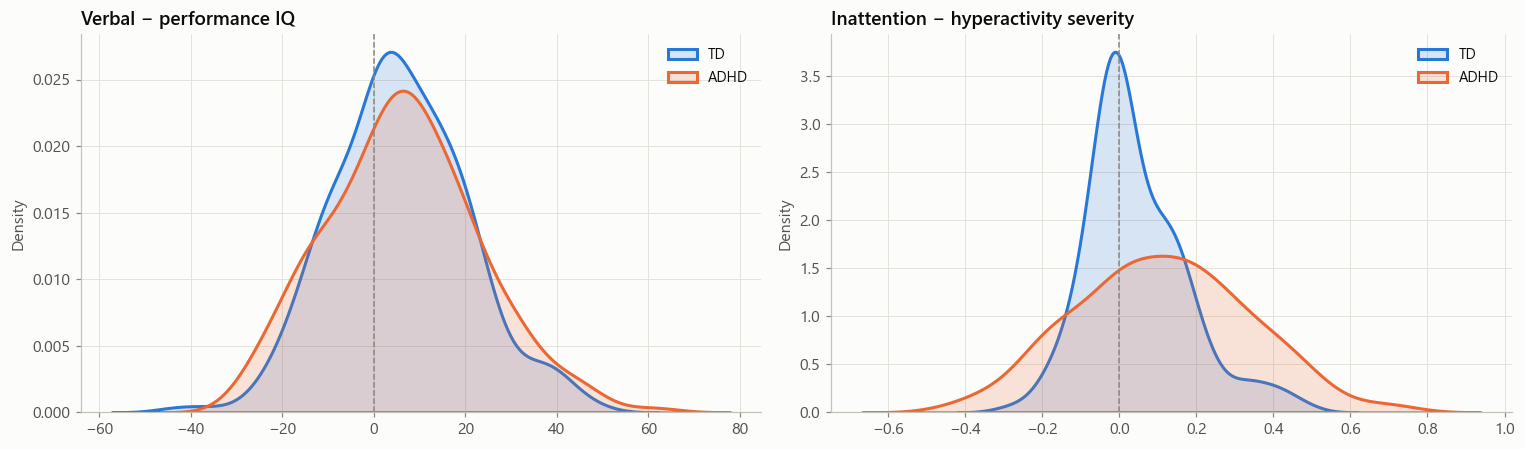

In [3]:
train = df[df.split == "train"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col, title in [(axes[0], "iq_discrepancy", "Verbal − performance IQ"), (axes[1], "inatt_minus_hyper", "Inattention − hyperactivity severity")]:
    for g, c, lab in [(0, TD_COLOR, "TD"), (1, ADHD_COLOR, "ADHD")]:
        sns.kdeplot(train.loc[train.adhd == g, col].dropna(), ax=ax, color=c, fill=True, alpha=0.18, lw=2, label=lab)
    ax.axvline(0, color=MUTED, lw=1, ls="--"); ax.set_title(title); ax.set_xlabel(""); ax.legend()
fig.tight_layout(); savefig(fig, "03_engineered_features"); plt.show()

## 3. Multicollinearity (VIF)

In [4]:
vif_cols = ["age", "sex_male", "handedness", "verbal_iq", "performance_iq", "full_iq", "iq_discrepancy"]
Xv = train[vif_cols].dropna()
Xv = (Xv - Xv.mean()) / Xv.std()
vif = pd.DataFrame({"feature": vif_cols,
                    "VIF": [variance_inflation_factor(Xv.values, i) for i in range(len(vif_cols))]}).round(2)
vif

,feature,VIF
0,age,1.02
1,sex_male,1.01
2,handedness,1.01
3,verbal_iq,inf
4,performance_iq,inf
5,full_iq,25.39
6,iq_discrepancy,inf


`iq_discrepancy` is *exactly* verbal − performance IQ, so those three have infinite VIF, and full-scale IQ is largely a combination of the two (VIF ≈ 25). Regularised logistic regression and tree models cope with this. For interpretation we rely on permutation importance and SHAP rather than raw coefficients.

## 4. Imputation strategy
Compared with logistic regression and random forest on **Set A** (no symptom ratings), 5-fold stratified CV, ROC-AUC.

In [5]:
def cv_auc(pipe, X, y):
    s = cross_val_score(pipe, X, y, cv=CV, scoring="roc_auc", n_jobs=-1)
    return s.mean(), s.std()

fsA = FEATURE_SETS["A_demographic_cognitive"]
XA, yA = train[fsA["numeric"]], train["adhd"]
rows = []
for imp in ["mean", "median", "knn", "iterative"]:
    for name, clf in [("Logistic Regression", LogisticRegression(max_iter=2000, class_weight="balanced")),
                      ("Random Forest", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))]:
        m, s = cv_auc(Pipeline([("prep", make_preprocessor(fsA["numeric"], [], imp)), ("clf", clf)]), XA, yA)
        rows.append({"imputer": imp, "model": name, "auc": m, "sd": s})
imp_res = pd.DataFrame(rows)
imp_res.pivot(index="imputer", columns="model", values="auc").round(4)

model,Logistic Regression,Random Forest
imputer,,
iterative,0.7354,0.7081
knn,0.7383,0.6938
mean,0.7343,0.7171
median,0.7349,0.7134


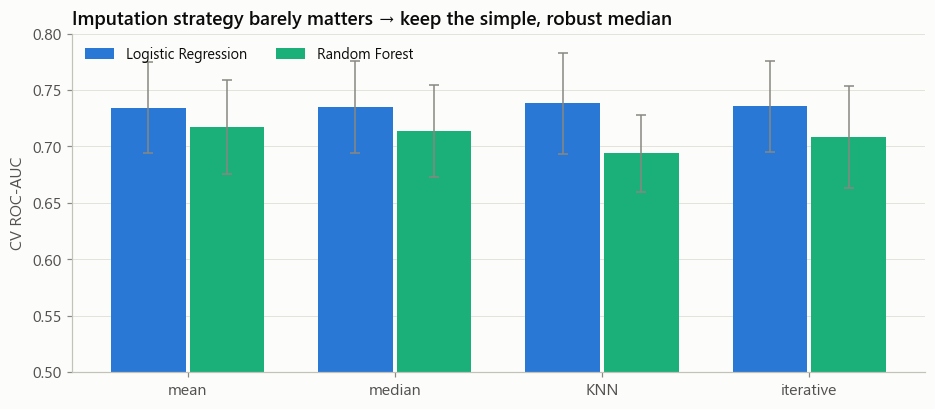

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(4); w = 0.36
for i, (model, c) in enumerate([("Logistic Regression", PALETTE[0]), ("Random Forest", PALETTE[2])]):
    r = imp_res[imp_res.model == model]
    ax.bar(x + (i - 0.5) * (w + 0.02), r.auc, w, yerr=r.sd, color=c, label=model, capsize=3, error_kw={"ecolor": MUTED, "lw": 1})
ax.set_xticks(x, ["mean", "median", "KNN", "iterative"]); ax.set_ylim(0.5, 0.8); ax.set_ylabel("CV ROC-AUC")
ax.grid(axis="x", visible=False); ax.legend(ncols=2, loc="upper left")
ax.set_title("Imputation strategy barely matters → keep the simple, robust median")
savefig(fig, "03_imputation_comparison"); plt.show()

## 5. Scaling
Tree models are scale-invariant; distance and kernel models are not. Compared on SVM (RBF).

In [7]:
rows = []
for sname, scaler in [("standard", StandardScaler()), ("robust", RobustScaler()), ("min-max", MinMaxScaler()), ("none", "passthrough")]:
    pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", scaler),
                     ("clf", SVC(class_weight="balanced", random_state=RANDOM_STATE))])
    m, s = cv_auc(pipe, XA, yA); rows.append({"scaler": sname, "SVM_auc": round(m, 4), "sd": round(s, 4)})
pd.DataFrame(rows)

,scaler,SVM_auc,sd
0,standard,0.7207,0.0443
1,robust,0.7194,0.0376
2,min-max,0.7318,0.0481
3,none,0.6695,0.0375


Without scaling the SVM collapses, because IQ (≈100) dominates the binary sex flag. Standard scaling is used everywhere.

## 6. Class imbalance

In [8]:
prep = lambda: make_preprocessor(fsA["numeric"], [], "median")
strategies = {
    "none": ImbPipeline([("prep", prep()), ("clf", LogisticRegression(max_iter=2000))]),
    "class_weight": ImbPipeline([("prep", prep()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "SMOTE": ImbPipeline([("prep", prep()), ("smote", SMOTE(random_state=RANDOM_STATE)), ("clf", LogisticRegression(max_iter=2000))]),
    "under-sample": ImbPipeline([("prep", prep()), ("rus", RandomUnderSampler(random_state=RANDOM_STATE)), ("clf", LogisticRegression(max_iter=2000))]),
}
rows = []
for name, pipe in strategies.items():
    res = {m: cross_val_score(pipe, XA, yA, cv=CV, scoring=m).mean() for m in ["roc_auc", "balanced_accuracy", "recall", "precision", "f1"]}
    rows.append({"strategy": name, **res})
imb = pd.DataFrame(rows).set_index("strategy").round(3)
imb

,roc_auc,balanced_accuracy,recall,precision,f1
strategy,,,,,
none,0.735,0.652,0.488,0.631,0.548
class_weight,0.735,0.666,0.669,0.556,0.606
SMOTE,0.733,0.660,0.662,0.547,0.598
under-sample,0.735,0.671,0.673,0.561,0.611


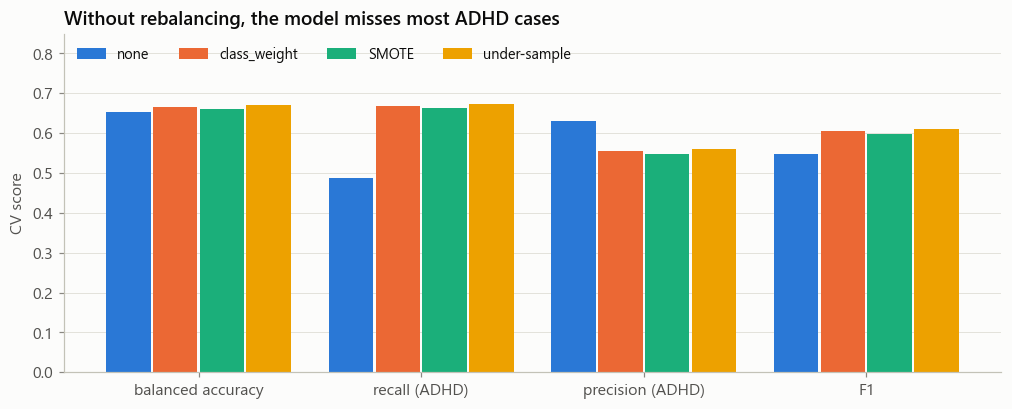

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
metrics = ["balanced_accuracy", "recall", "precision", "f1"]
x = np.arange(len(metrics)); w = 0.2
for i, (s, c) in enumerate(zip(imb.index, PALETTE)):
    ax.bar(x + (i - 1.5) * (w + 0.01), imb.loc[s, metrics], w, color=c, label=s)
ax.set_xticks(x, ["balanced accuracy", "recall (ADHD)", "precision (ADHD)", "F1"]); ax.set_ylim(0, 0.85)
ax.grid(axis="x", visible=False); ax.legend(ncols=4, loc="upper left"); ax.set_ylabel("CV score")
ax.set_title("Without rebalancing, the model misses most ADHD cases")
savefig(fig, "03_imbalance_comparison"); plt.show()

Rebalancing leaves ROC-AUC unchanged (it is threshold-free) but **more than doubles ADHD recall**. `class_weight="balanced"` matches SMOTE without generating synthetic children, so it is the default; SMOTE stays available as a tuning option.

## 7. Feature selection

In [10]:
fsB = FEATURE_SETS["B_with_symptom_ratings"]
trainB = train[train.rating_scale.notna()]
XB = SimpleImputer(strategy="median").fit_transform(trainB[fsB["numeric"]])
yB = trainB["adhd"].values
mi = mutual_info_classif(XB, yB, random_state=RANDOM_STATE)
f, _ = f_classif(XB, yB)
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.1).fit(StandardScaler().fit_transform(XB), yB)
sel = pd.DataFrame({"feature": fsB["numeric"], "mutual_info": mi, "anova_F": f, "L1_coef": l1.coef_[0]}).sort_values("mutual_info", ascending=False)
sel.round(3)

,feature,mutual_info,anova_F,L1_coef
9,adhd_index_sev,0.563,852.673,3.140
10,inattentive_sev,0.525,659.258,0.121
11,hyper_impulsive_sev,0.388,384.878,0.000
12,inatt_minus_hyper,0.090,12.971,0.000
5,full_iq,0.062,39.405,-0.190
3,verbal_iq,0.054,28.589,-0.068
4,performance_iq,0.050,30.322,0.000
8,age_sq,0.035,0.007,0.000
1,sex_male,0.020,30.035,0.194
7,iq_missing,0.012,0.587,0.000


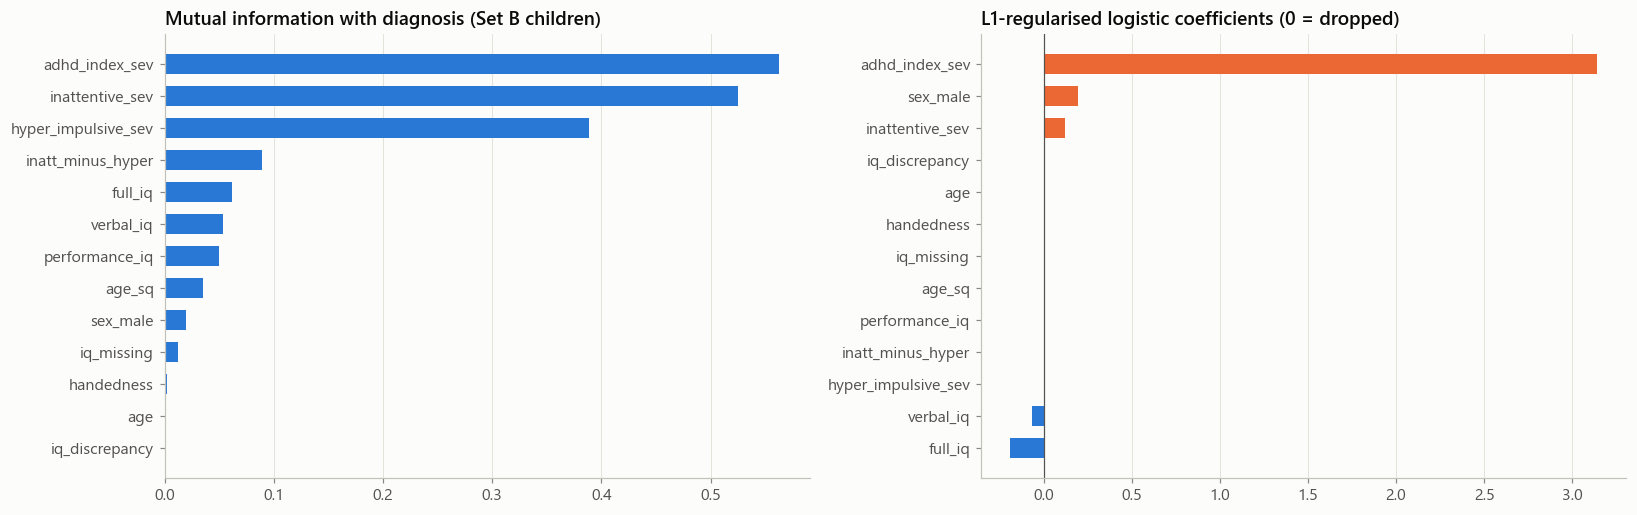

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
s = sel.sort_values("mutual_info")
axes[0].barh(s.feature, s.mutual_info, color=PALETTE[0], height=0.62)
axes[0].set_title("Mutual information with diagnosis (Set B children)"); axes[0].grid(axis="y", visible=False)
s = sel.sort_values("L1_coef")
axes[1].barh(s.feature, s.L1_coef, color=[ADHD_COLOR if v > 0 else TD_COLOR for v in s.L1_coef], height=0.62)
axes[1].axvline(0, color=INK_2, lw=0.8); axes[1].grid(axis="y", visible=False)
axes[1].set_title("L1-regularised logistic coefficients (0 = dropped)")
fig.tight_layout(); savefig(fig, "03_feature_selection"); plt.show()

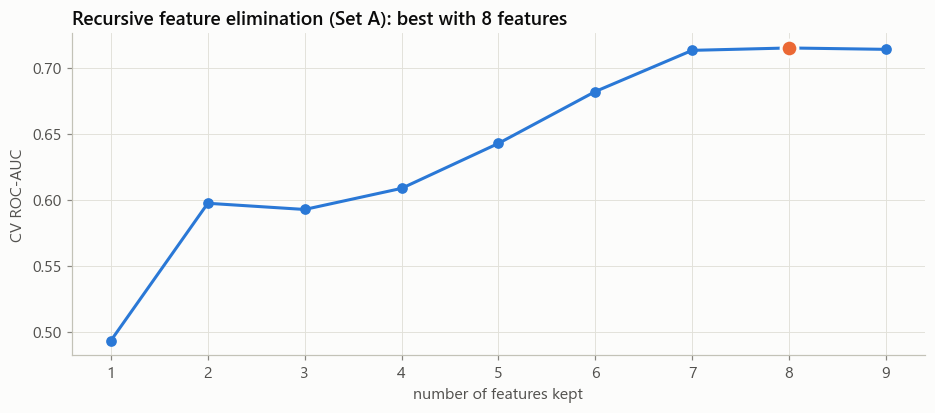

Selected: [np.str_('age'), np.str_('sex_male'), np.str_('verbal_iq'), np.str_('performance_iq'), np.str_('full_iq'), np.str_('iq_discrepancy'), np.str_('iq_missing'), np.str_('age_sq')]


In [12]:
XA_imp = SimpleImputer(strategy="median").fit_transform(XA)
rfecv = RFECV(RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
              step=1, cv=CV, scoring="roc_auc", min_features_to_select=1, n_jobs=-1).fit(XA_imp, yA)
scores = rfecv.cv_results_["mean_test_score"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(range(1, len(scores) + 1), scores, color=PALETTE[0], marker="o", ms=6)
ax.scatter([rfecv.n_features_], [scores[rfecv.n_features_ - 1]], s=120, color=ADHD_COLOR, zorder=3, edgecolor=SURFACE, lw=2)
ax.set_xlabel("number of features kept"); ax.set_ylabel("CV ROC-AUC")
ax.set_title(f"Recursive feature elimination (Set A): best with {rfecv.n_features_} features")
savefig(fig, "03_rfecv"); plt.show()
print("Selected:", list(np.array(fsA["numeric"])[rfecv.support_]))

**Takeaways**
- In Set B, the three symptom severities carry almost all the information. L1 keeps them and shrinks most demographic/IQ terms toward zero.
- In Set A, RFECV shows the curve is fairly flat after a handful of features, so the full engineered set is kept (it is small) and regularisation does the rest.

## 8. Save the configuration & splits

In [13]:
config = {
    "split": {"test_size": 0.20, "stratify": "site x diagnosis", "random_state": RANDOM_STATE,
              "n_train": int((df.split == "train").sum()), "n_test": int((df.split == "test").sum())},
    "imputer": "median", "scaler": "standard", "imbalance": "class_weight=balanced",
    "feature_sets": FEATURE_SETS,
    "rfecv_selected_setA": list(np.array(fsA["numeric"])[rfecv.support_]),
    "imputation_cv": imp_res.round(4).to_dict(orient="records"),
    "imbalance_cv": imb.reset_index().to_dict(orient="records"),
}
(REPORTS / "preprocessing_config.json").write_text(json.dumps(config, indent=2))
df.to_csv(DATA_PROCESSED / "adhd200_model_ready.csv", index=False)
print(json.dumps(config["split"], indent=2))

{
  "test_size": 0.2,
  "stratify": "site x diagnosis",
  "random_state": 42,
  "n_train": 748,
  "n_test": 187
}


## Summary
- Locked **80 / 20** split, stratified by site × diagnosis.
- **Median imputation + standard scaling + balanced class weights**, all inside pipelines.
- Four engineered features; two feature sets (A: no questionnaire, B: with symptom ratings).

**Next:** `04_model_training_evaluation.ipynb`